# 01. EDA и подготовка данных

**Цель ноутбука**
- Загрузить датасет Hillstrom (customer-retention)
- Провести разведочный анализ
- Сделать feature engineering
- Стратифицированный train/test split
- Сохранить preprocessor и подготовленные массивы

**Датасет**: https://www.kaggle.com/datasets/davinwijaya/customer-retention

In [1]:
import sys
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

# Добавляем корень проекта в path
PROJECT_ROOT = Path().resolve().parents[0]
sys.path.insert(0, str(PROJECT_ROOT))

from src.preprocessing import load_raw_data, create_features, prepare_train_test

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)
pd.set_option("display.max_columns", 30)

print("Project root:", PROJECT_ROOT)

Project root: /Users/bariatmamaeva/Downloads/Uplift-Project


## 1. Загрузка данных

In [2]:
df = load_raw_data()
print(f"Shape: {df.shape}")
df.head()

Shape: (64000, 9)


,recency,history,used_discount,used_bogo,zip_code,is_referral,channel,offer,conversion
0,10,142.44,1,0,Suburban,0,Phone,Buy One Get One,0
1,6,329.08,1,1,Rural,1,Web,No Offer,0
2,7,180.65,0,1,Suburban,1,Web,Buy One Get One,0
3,9,675.83,1,0,Rural,1,Web,Discount,0
4,2,45.34,1,0,Urban,0,Web,Buy One Get One,0


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 64000 entries, 0 to 63999
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   recency        64000 non-null  int64  
 1   history        64000 non-null  float64
 2   used_discount  64000 non-null  int64  
 3   used_bogo      64000 non-null  int64  
 4   zip_code       64000 non-null  object 
 5   is_referral    64000 non-null  int64  
 6   channel        64000 non-null  object 
 7   offer          64000 non-null  object 
 8   conversion     64000 non-null  int64  
dtypes: float64(1), int64(5), object(3)
memory usage: 4.4+ MB


In [4]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
recency,64000.0,NaN,NaN,NaN,5.763734,3.507592,1.0,2.0,6.0,9.0,12.0
history,64000.0,NaN,NaN,NaN,242.085656,256.158608,29.99,64.66,158.11,325.6575,3345.93
used_discount,64000.0,NaN,NaN,NaN,0.551031,0.497393,0.0,0.0,1.0,1.0,1.0
used_bogo,64000.0,NaN,NaN,NaN,0.549719,0.497526,0.0,0.0,1.0,1.0,1.0
zip_code,64000,3,Suburban,28776,NaN,NaN,NaN,NaN,NaN,NaN,NaN
is_referral,64000.0,NaN,NaN,NaN,0.50225,0.499999,0.0,0.0,1.0,1.0,1.0
channel,64000,3,Web,28217,NaN,NaN,NaN,NaN,NaN,NaN,NaN
offer,64000,3,Buy One Get One,21387,NaN,NaN,NaN,NaN,NaN,NaN,NaN
conversion,64000.0,NaN,NaN,NaN,0.146781,0.35389,0.0,0.0,0.0,0.0,1.0


## 2. EDA

In [5]:
print("Conversion rate overall:", df["conversion"].mean().round(4))
print("\nOffer distribution:")
print(df["offer"].value_counts(normalize=True).round(3))
print("\nConversion by offer:")
print(df.groupby("offer")["conversion"].mean().round(4))

Conversion rate overall: 0.1468

Offer distribution:
offer
Buy One Get One    0.334
Discount           0.333
No Offer           0.333
Name: proportion, dtype: float64

Conversion by offer:
offer
Buy One Get One    0.1514
Discount           0.1828
No Offer           0.1062
Name: conversion, dtype: float64


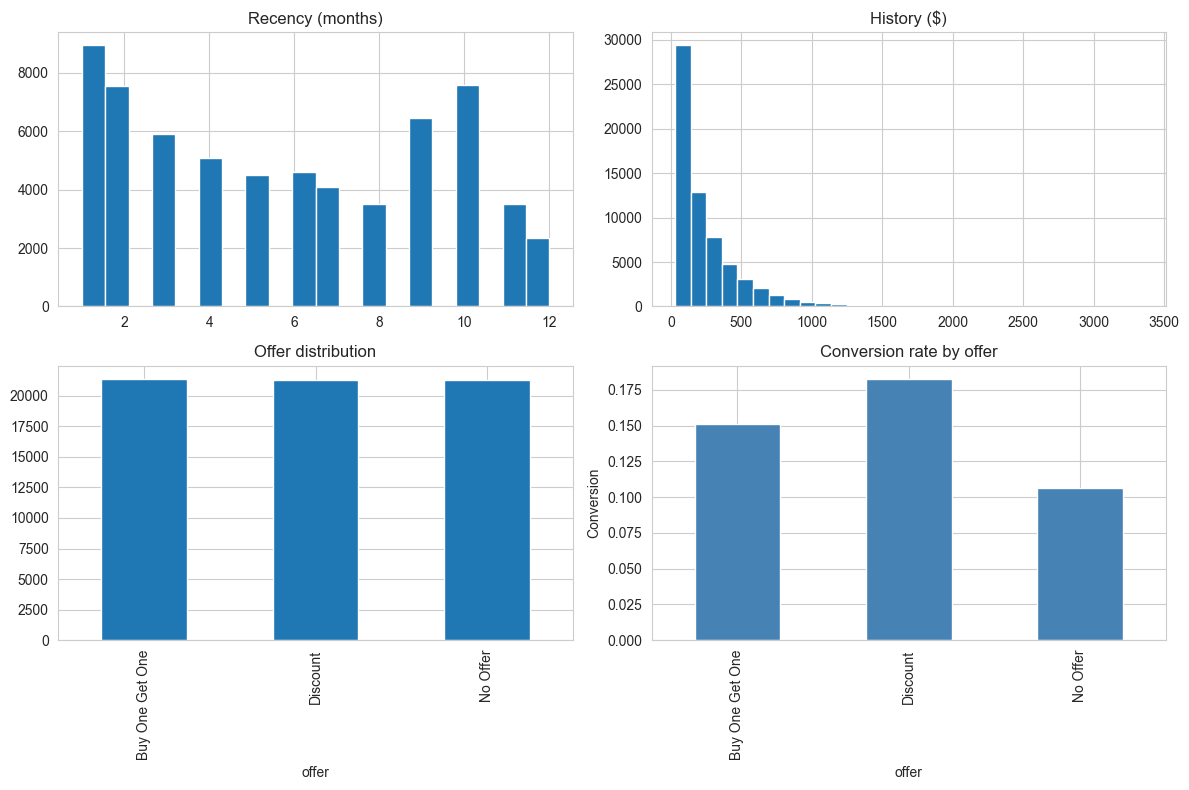

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

df["recency"].hist(ax=axes[0, 0], bins=20)
axes[0, 0].set_title("Recency (months)")

df["history"].hist(ax=axes[0, 1], bins=30)
axes[0, 1].set_title("History ($)")

df["offer"].value_counts().plot(kind="bar", ax=axes[1, 0])
axes[1, 0].set_title("Offer distribution")

df.groupby("offer")["conversion"].mean().plot(kind="bar", ax=axes[1, 1], color="steelblue")
axes[1, 1].set_title("Conversion rate by offer")
axes[1, 1].set_ylabel("Conversion")

plt.tight_layout()
plt.savefig(PROJECT_ROOT / "figures" / "01_eda_overview.png", dpi=120, bbox_inches="tight")
plt.show()

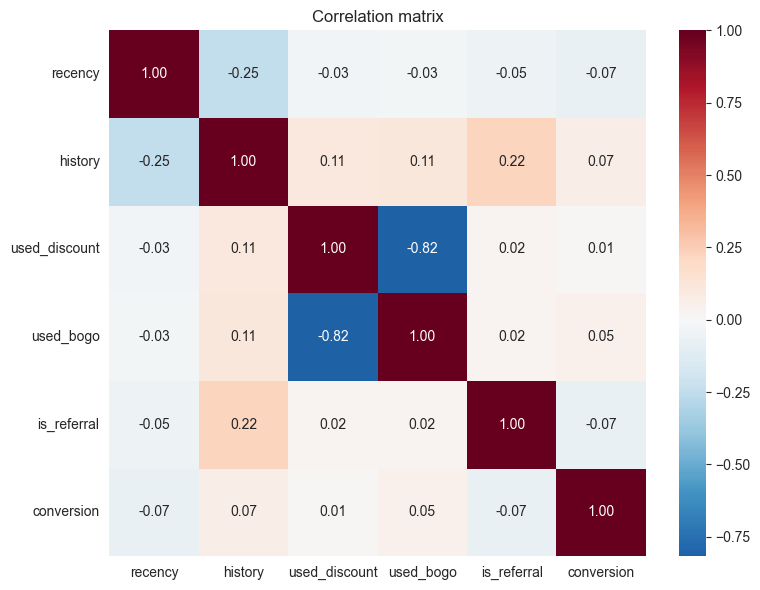

In [7]:
corr_cols = ["recency", "history", "used_discount", "used_bogo", "is_referral", "conversion"]
corr = df[corr_cols].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, cmap="RdBu_r", center=0, fmt=".2f")
plt.title("Correlation matrix")
plt.tight_layout()
plt.savefig(PROJECT_ROOT / "figures" / "01_correlation.png", dpi=120, bbox_inches="tight")
plt.show()

## 3. Feature Engineering + Train/Test Split

In [8]:
data = prepare_train_test(df, test_size=0.2, random_state=42)

print("Train size:", data["X_train"].shape)
print("Test size :", data["X_test"].shape)
print("\nTreatment rate train:", data["t_train"].mean().round(4))
print("Treatment rate test :", data["t_test"].mean().round(4))
print("Conversion rate train:", data["y_train"].mean().round(4))
print("Conversion rate test :", data["y_test"].mean().round(4))
print("\nFeature names (first 10):", data["feature_names"][:10])

Train size: (51200, 15)
Test size : (12800, 15)

Treatment rate train: 0.6671
Treatment rate test : 0.6671
Conversion rate train: 0.1468
Conversion rate test : 0.1467

Feature names (first 10): ['num__recency', 'num__history', 'num__used_discount', 'num__used_bogo', 'num__is_referral', 'num__history_discount', 'num__history_bogo', 'num__recency_history', 'num__history_log', 'cat__zip_code_Rural']


## 4. Сохранение артефактов

In [9]:
artifacts_dir = PROJECT_ROOT / "outputs"
artifacts_dir.mkdir(exist_ok=True)

joblib.dump(data["preprocessor"], PROJECT_ROOT / "models" / "preprocessor.joblib")
joblib.dump(
    {
        "X_train": data["X_train"],
        "X_test": data["X_test"],
        "y_train": data["y_train"],
        "y_test": data["y_test"],
        "t_train": data["t_train"],
        "t_test": data["t_test"],
        "idx_train": data["idx_train"],
        "idx_test": data["idx_test"],
        "feature_names": data["feature_names"],
    },
    artifacts_dir / "prepared_data.joblib",
)

# Также сохраняем полный df с treatment для последующего анализа
data["df_full"].to_parquet(artifacts_dir / "df_full.parquet", index=True)

print("Saved:")
print(" - models/preprocessor.joblib")
print(" - outputs/prepared_data.joblib")
print(" - outputs/df_full.parquet")

Saved:
 - models/preprocessor.joblib
 - outputs/prepared_data.joblib
 - outputs/df_full.parquet


## Выводы EDA

- Датасет сбалансирован по treatment (~2/3 получили offer).
- Conversion в группе No Offer ниже, чем в Discount / BOGO — есть положительный average treatment effect.
- `history` сильно скошен → используем log-трансформацию.
- Признаки `used_discount` / `used_bogo` информативны для uplift (история реакции на акции).